# Unemployment Analysis in India (CodeAlpha Data Science Internship, Task 2)

**Goal:** clean and explore India's unemployment data, measure the impact of Covid-19, look for seasonal patterns, and draw out insights that could inform economic and social policy.

**Data:** state-level monthly estimates, May 2019 to June 2020, split into rural and urban areas (unemployment rate, estimated employed, labour participation rate).

**Contents**
1. Load and inspect
2. Clean
3. National trend
4. Rural vs urban
5. Covid-19 impact by state
6. Employment and labour participation
7. Seasonality check
8. Insights for policy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8a86'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'font.size': 10,
})
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load and inspect

In [2]:
raw = pd.read_csv('Unemployment in India.csv', encoding='utf-8-sig')
print('Shape:', raw.shape)
print()
print(raw.dtypes)
raw.head()

Shape: (768, 7)

Region                                          str
 Date                                           str
 Frequency                                      str
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                            str
dtype: object


           Region         Date  Frequency   Estimated Unemployment Rate (%)   Estimated Employed  \
0  Andhra Pradesh   31-05-2019    Monthly                              3.65           11999139.0   
1  Andhra Pradesh   30-06-2019    Monthly                              3.05           11755881.0   
2  Andhra Pradesh   31-07-2019    Monthly                              3.75           12086707.0   
3  Andhra Pradesh   31-08-2019    Monthly                              3.32           12285693.0   
4  Andhra Pradesh   30-09-2019    Monthly                              5.17           12256762.0   

    Estimated Labour Participation Rate (%)   Area  
0                                     43.24  Rural  
1                                     42.05  Rural  
2                                     43.50  Rural  
3                                     43.97  Rural  
4                                     44.68  Rural  

In [3]:
print('Fully blank rows:', raw.isna().all(axis=1).sum())
print()
print('Column names as loaded:', list(raw.columns))
print('Frequency values:', raw[' Frequency'].unique())
print('Date sample:', raw[' Date'].dropna().unique()[:3])

Fully blank rows: 28

Column names as loaded: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
Frequency values: <StringArray>
[' Monthly', nan, 'Monthly']
Length: 3, dtype: str
Date sample: <StringArray>
[' 31-05-2019', ' 30-06-2019', ' 31-07-2019']
Length: 3, dtype: str


Things to fix: the file has fully blank rows, column names and text values carry stray spaces, and `Date` is stored as text with a leading space.

## 2. Clean

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'Estimated Unemployment Rate (%)': 'UnemploymentRate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'LabourParticipation',
})

blank_rows = int(df.isna().all(axis=1).sum())
df = df.dropna(how='all').copy()

for col in ['Region', 'Frequency', 'Area']:
    df[col] = df[col].str.strip()

df['Date'] = pd.to_datetime(df['Date'].str.strip(), format='%d-%m-%Y')
# Each reading is a month-end snapshot; use the first of the month so every
# point sits on its own month tick when plotted.
df['Date'] = df['Date'].dt.to_period('M').dt.to_timestamp()
df = df.sort_values(['Region', 'Area', 'Date']).reset_index(drop=True)

# Periods: the national lockdown began on 25 March 2020
df['Period'] = np.select(
    [df['Date'] < '2020-03-01', df['Date'] < '2020-04-01'],
    ['Pre-Covid', 'Transition (Mar 2020)'],
    default='Lockdown (Apr-Jun 2020)')

print('Blank rows dropped:', blank_rows)
print('Rows now:', len(df))
print('Duplicate rows:', df.duplicated().sum())
print('Missing values:', int(df.isna().sum().sum()))
print('Regions:', df['Region'].nunique(), '| Months:', df['Date'].nunique(),
      '| Range:', df['Date'].min().date(), 'to', df['Date'].max().date())

Blank rows dropped: 28
Rows now: 740
Duplicate rows: 0
Missing values: 0
Regions: 28 | Months: 14 | Range: 2019-05-01 to 2020-06-01


In [5]:
rows_per_region = df.groupby('Region').size().sort_values()
full = df['Region'].nunique() * 2 * df['Date'].nunique()
print(f'{len(df)} rows vs {full} if every region had rural and urban data every month')
print()
print('Regions with incomplete coverage (rows out of 28):')
print(rows_per_region[rows_per_region < 28].to_string())
print()
print('Rows with an unemployment rate of exactly 0:', int((df['UnemploymentRate'] == 0).sum()))

740 rows vs 784 if every region had rural and urban data every month

Regions with incomplete coverage (rows out of 28):
Region
Chandigarh         12
Sikkim             17
Jammu & Kashmir    21
Goa                24
Puducherry         26
Assam              26
Uttarakhand        27
Meghalaya          27

Rows with an unemployment rate of exactly 0: 11


Coverage is uneven: a few regions (Chandigarh, Sikkim, Jammu & Kashmir, Goa, Puducherry and others) are missing months. Rate comparisons are safe, but totals such as "employed" must be compared on a fixed set of regions (done in section 6). The zero rates are mostly tiny rural samples in small regions; they are kept because they are valid survey readings.

In [6]:
df[['UnemploymentRate', 'Employed', 'LabourParticipation']].describe().round(2)

       UnemploymentRate     Employed  LabourParticipation
count            740.00       740.00               740.00
mean              11.79   7204460.03                42.63
std               10.72   8087988.43                 8.11
min                0.00     49420.00                13.33
25%                4.66   1190404.50                38.06
50%                8.35   4744178.50                41.16
75%               15.89  11275489.50                45.50
max               76.74  45777509.00                72.57

## 3. National trend

Two views of the national rate: the simple average across all state and area readings, and a **labour-force-weighted** rate (labour force = employed / (1 - rate)), which gives bigger states proportionally more weight.

In [7]:
df['LabourForce'] = df['Employed'] / (1 - df['UnemploymentRate'] / 100)
nat = df.groupby('Date').agg(simple=('UnemploymentRate', 'mean'),
                             employed=('Employed', 'sum'),
                             labour_force=('LabourForce', 'sum'))
nat['weighted'] = 100 * (1 - nat['employed'] / nat['labour_force'])
print(nat[['simple', 'weighted']].round(2).to_string())

            simple  weighted
Date                        
2019-05-01    8.87      7.04
2019-06-01    9.30      7.88
2019-07-01    9.03      7.37
2019-08-01    9.64      8.08
2019-09-01    9.05      7.08
2019-10-01    9.90      8.11
2019-11-01    9.87      7.25
2019-12-01    9.50      7.73
2020-01-01    9.95      7.24
2020-02-01    9.96      7.78
2020-03-01   10.70      8.67
2020-04-01   23.64     24.16
2020-05-01   24.88     23.57
2020-06-01   11.90     11.04


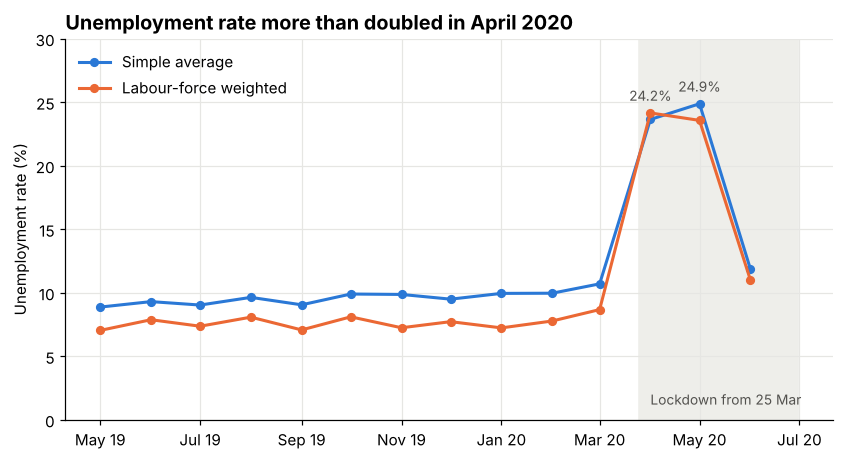

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-06-30'), color='#eeeeea', zorder=0)
ax.text(pd.Timestamp('2020-04-01'), 1.2, 'Lockdown from 25 Mar', fontsize=9, color='#52514e')
ax.plot(nat.index, nat['simple'], color=BLUE, lw=2, marker='o', ms=5, label='Simple average')
ax.plot(nat.index, nat['weighted'], color=ORANGE, lw=2, marker='o', ms=5, label='Labour-force weighted')
for s, c in [('simple', BLUE), ('weighted', ORANGE)]:
    pk = nat[s].idxmax()
    ax.annotate(f'{nat[s].max():.1f}%', (pk, nat[s].max()), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=9, color='#52514e')
ax.set_ylim(0, 30)
ax.set_ylabel('Unemployment rate (%)')
ax.set_title('Unemployment rate more than doubled in April 2020')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.legend(frameon=False, loc='upper left')
plt.show()

## 4. Rural vs urban

In [9]:
area = df.pivot_table(index='Date', columns='Area', values='UnemploymentRate', aggfunc='mean')
area['Gap (urban - rural)'] = area['Urban'] - area['Rural']
print(area.round(2).to_string())

Area        Rural  Urban  Gap (urban - rural)
Date                                         
2019-05-01   7.07  10.55                 3.48
2019-06-01   8.20  10.33                 2.13
2019-07-01   7.74  10.23                 2.49
2019-08-01   8.50  10.73                 2.23
2019-09-01   7.04  10.92                 3.88
2019-10-01   9.05  10.72                 1.67
2019-11-01   8.43  11.25                 2.82
2019-12-01   8.23  10.63                 2.39
2020-01-01   7.84  11.98                 4.14
2020-02-01   8.75  11.13                 2.38
2020-03-01   9.68  11.57                 1.89
2020-04-01  21.75  25.46                 3.72
2020-05-01  21.21  28.40                 7.19
2020-06-01  11.83  11.98                 0.16


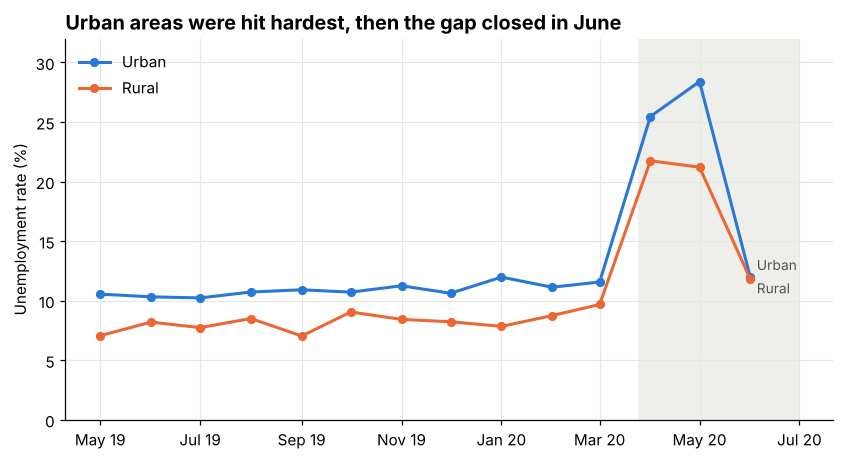

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-06-30'), color='#eeeeea', zorder=0)
ax.plot(area.index, area['Urban'], color=BLUE, lw=2, marker='o', ms=5, label='Urban')
ax.plot(area.index, area['Rural'], color=ORANGE, lw=2, marker='o', ms=5, label='Rural')
ax.text(area.index[-1] + pd.Timedelta(days=4), area['Urban'].iloc[-1] + 0.6, 'Urban', color='#52514e', fontsize=9)
ax.text(area.index[-1] + pd.Timedelta(days=4), area['Rural'].iloc[-1] - 1.2, 'Rural', color='#52514e', fontsize=9)
ax.set_ylim(0, 32)
ax.set_ylabel('Unemployment rate (%)')
ax.set_title('Urban areas were hit hardest, then the gap closed in June')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.legend(frameon=False, loc='upper left')
plt.show()

## 5. Covid-19 impact by state

In [11]:
pre = df[df['Period'] == 'Pre-Covid']
lock = df[df['Period'] == 'Lockdown (Apr-Jun 2020)']

impact = pd.concat([
    pre.groupby('Region')['UnemploymentRate'].mean().rename('Pre-Covid'),
    lock.groupby('Region')['UnemploymentRate'].mean().rename('Lockdown'),
], axis=1)
impact['Change (pts)'] = impact['Lockdown'] - impact['Pre-Covid']
impact = impact.sort_values('Change (pts)', ascending=False)
print(impact.round(2).to_string())

                  Pre-Covid  Lockdown  Change (pts)
Region                                             
Puducherry             1.59     57.70         56.11
Jharkhand             14.28     44.90         30.62
Tamil Nadu             2.84     31.74         28.90
Bihar                 13.83     36.99         23.16
Karnataka              3.23     19.16         15.92
Haryana               22.94     37.69         14.76
Telangana              4.66     18.64         13.98
Kerala                 6.99     20.94         13.95
Madhya Pradesh         4.74     17.76         13.02
Andhra Pradesh         5.04     15.78         10.74
Maharashtra            5.37     15.42         10.05
Delhi                 14.23     24.17          9.93
Uttar Pradesh         10.62     19.56          8.94
Odisha                 3.41     11.87          8.46
Goa                    8.51     15.89          7.38
West Bengal            6.57     13.73          7.16
Chhattisgarh           7.71     14.85          7.14
Gujarat     

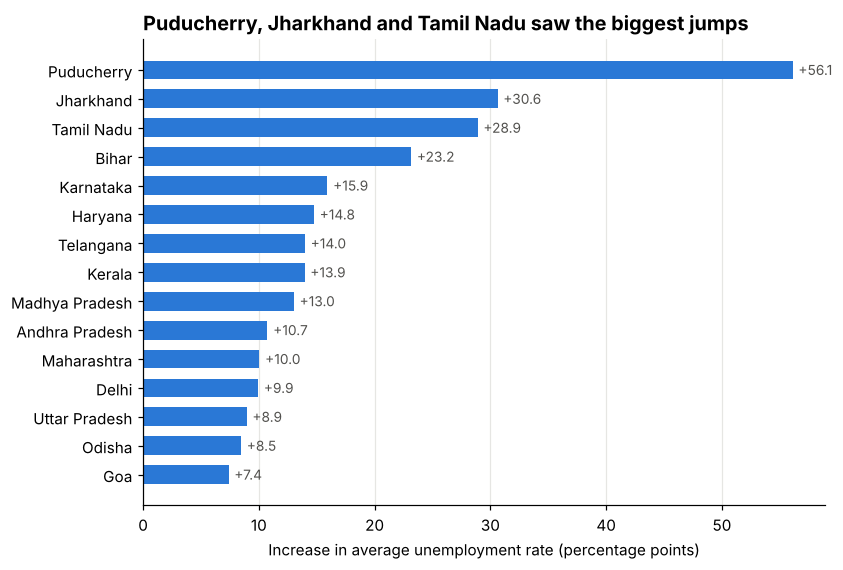

In [12]:
top = impact.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top['Change (pts)'], color=BLUE, height=0.65)
for y, v in enumerate(top['Change (pts)']):
    ax.text(v + 0.5, y, f'+{v:.1f}', va='center', fontsize=9, color='#52514e')
ax.set_xlabel('Increase in average unemployment rate (percentage points)')
ax.set_title('Puducherry, Jharkhand and Tamil Nadu saw the biggest jumps')
ax.grid(axis='y', visible=False)
plt.show()

In [13]:
n_down = int((impact['Change (pts)'] < 0).sum())
print('Regions where the average rate fell during lockdown:', n_down,
      '->', ', '.join(impact[impact['Change (pts)'] < 0].index))
print()

a = pre['UnemploymentRate']
b = lock['UnemploymentRate']
print(f'Mean rate pre-Covid: {a.mean():.2f}%   lockdown: {b.mean():.2f}%')
print('Welch t-test:        ', stats.ttest_ind(b, a, equal_var=False))
print('Mann-Whitney U test: ', stats.mannwhitneyu(b, a, alternative='greater'))

Regions where the average rate fell during lockdown: 4 -> Tripura, Himachal Pradesh, Jammu & Kashmir, Chandigarh

Mean rate pre-Covid: 9.51%   lockdown: 20.19%
Welch t-test:         TtestResult(statistic=np.float64(7.9138742453407405), pvalue=np.float64(3.1286093203645784e-13), df=np.float64(169.075912408179))
Mann-Whitney U test:  MannwhitneyuResult(statistic=np.float64(58797.5), pvalue=np.float64(3.3945911846107154e-17))


Both tests point the same way. Treat the p-values as indicative only: readings from the same region and month are not independent.

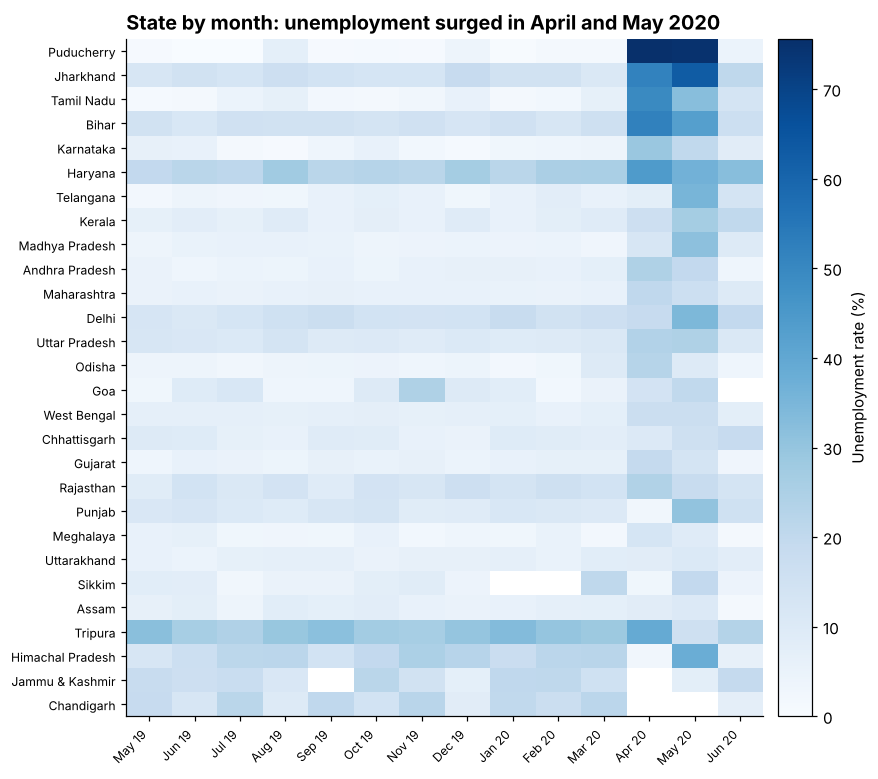

In [14]:
heat = df.pivot_table(index='Region', columns='Date', values='UnemploymentRate', aggfunc='mean')
heat = heat.loc[impact.index]   # worst-hit at the top
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(heat.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index, fontsize=8)
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([d.strftime('%b %y') for d in heat.columns], rotation=45, ha='right', fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label('Unemployment rate (%)')
ax.set_title('State by month: unemployment surged in April and May 2020')
plt.show()

White cells mean there is no reading for that region and month.

## 6. Employment and labour participation

Because some regions have missing months, totals are compared on the regions with complete data (rural and urban, all 14 months). That keeps the series like-for-like.

In [15]:
complete = rows_per_region[rows_per_region == rows_per_region.max()].index
bal = df[df['Region'].isin(complete)]
print(f'{len(complete)} of {df.Region.nunique()} regions have complete data')

emp = bal.groupby('Date')['Employed'].sum() / 1e6
lfpr = bal.groupby('Date')['LabourParticipation'].mean()

feb, apr, jun = pd.Timestamp('2020-02-01'), pd.Timestamp('2020-04-01'), pd.Timestamp('2020-06-01')
print(f'Employed (million): Feb 2020 {emp[feb]:.0f} -> Apr 2020 {emp[apr]:.0f} -> Jun 2020 {emp[jun]:.0f}')
print(f'Change Feb to Apr: {100 * (emp[apr] / emp[feb] - 1):.1f}%   recovered by Jun: {100 * (emp[jun] / emp[feb] - 1):.1f}% vs Feb')
print(f'Labour participation: Feb {lfpr[feb]:.1f}% -> Apr {lfpr[apr]:.1f}% -> Jun {lfpr[jun]:.1f}%')

20 of 28 regions have complete data
Employed (million): Feb 2020 384 -> Apr 2020 263 -> Jun 2020 354
Change Feb to Apr: -31.4%   recovered by Jun: -7.9% vs Feb
Labour participation: Feb 44.3% -> Apr 33.8% -> Jun 41.1%


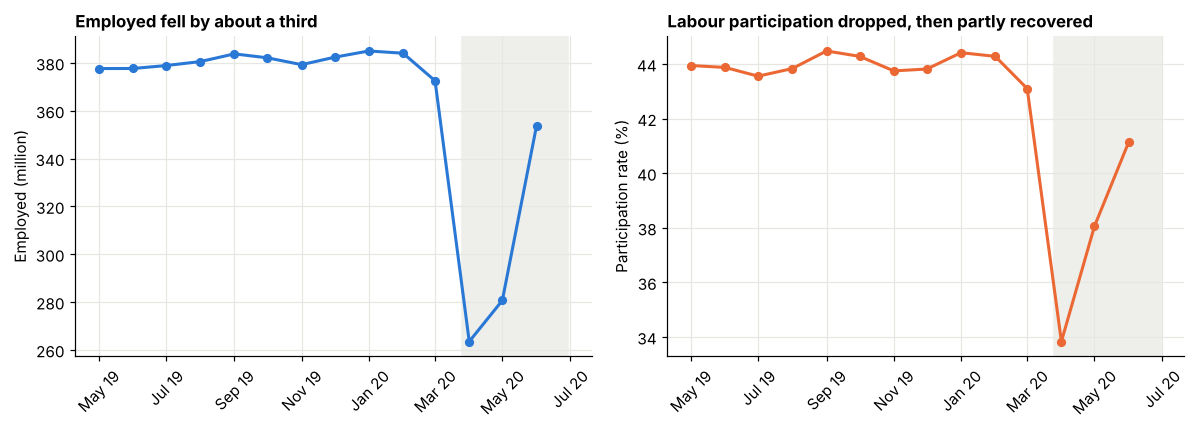

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, series, color, title, yl in [
    (axes[0], emp, BLUE, 'Employed fell by about a third', 'Employed (million)'),
    (axes[1], lfpr, ORANGE, 'Labour participation dropped, then partly recovered', 'Participation rate (%)'),
]:
    ax.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-06-30'), color='#eeeeea', zorder=0)
    ax.plot(series.index, series.values, color=color, lw=2, marker='o', ms=5)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(yl)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 7. Seasonality check

The data covers only 14 months, so one full seasonal cycle is not available. Two checks are still useful: (a) how much the rate moves month to month **before** Covid, and (b) like-for-like months (May and June) in 2019 vs 2020.

In [17]:
pre_area = pre.pivot_table(index='Date', columns='Area', values='UnemploymentRate', aggfunc='mean')
print('Pre-Covid monthly range by area (min - max, std):')
for a_ in pre_area.columns:
    print(f'  {a_:6s} {pre_area[a_].min():.1f}% - {pre_area[a_].max():.1f}%   std {pre_area[a_].std():.2f}')
print()

same = df[df['Date'].dt.month.isin([5, 6])].copy()
same['Year'] = same['Date'].dt.year
cmp_ = same.pivot_table(index=same['Date'].dt.strftime('%b'), columns='Year',
                        values='UnemploymentRate', aggfunc='mean').round(2)
cmp_['Change (pts)'] = cmp_[2020] - cmp_[2019]
print('Same month, different year (average rate %):')
print(cmp_.to_string())

Pre-Covid monthly range by area (min - max, std):
  Rural  7.0% - 9.1%   std 0.67
  Urban  10.2% - 12.0%   std 0.51

Same month, different year (average rate %):
Year  2019   2020  Change (pts)
Date                           
Jun   9.30  11.90          2.60
May   8.87  24.88         16.01


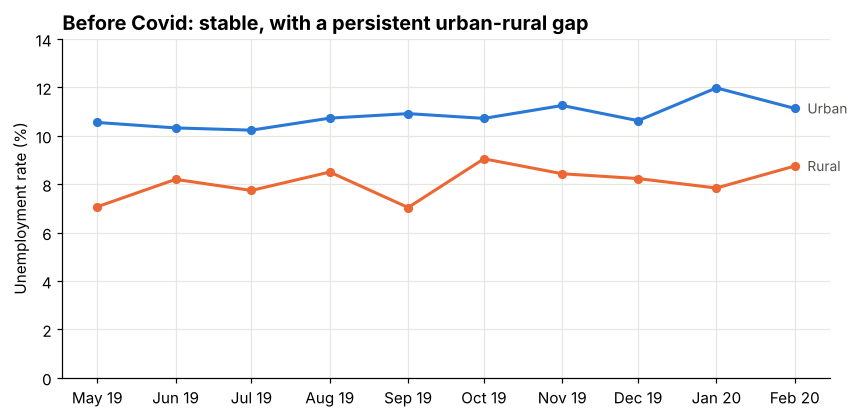

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pre_area.index, pre_area['Urban'], color=BLUE, lw=2, marker='o', ms=5)
ax.plot(pre_area.index, pre_area['Rural'], color=ORANGE, lw=2, marker='o', ms=5)
ax.text(pre_area.index[-1] + pd.Timedelta(days=5), pre_area['Urban'].iloc[-1], 'Urban', color='#52514e', fontsize=9, va='center')
ax.text(pre_area.index[-1] + pd.Timedelta(days=5), pre_area['Rural'].iloc[-1], 'Rural', color='#52514e', fontsize=9, va='center')
ax.set_ylim(0, 14)
ax.set_ylabel('Unemployment rate (%)')
ax.set_title('Before Covid: stable, with a persistent urban-rural gap')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
plt.show()

## 8. Insights for policy

### What the data shows

1. **Covid-19 caused a sharp, short shock.** The average unemployment rate was 9.5% before Covid and 20.2% during the April to June 2020 lockdown. The monthly national average peaked at 24.9% in May 2020 (24.2% in April on the labour-force-weighted view) and fell back to about 11.9% by June, still above the pre-Covid level.
2. **The unemployment rate understates the damage in April.** On the 20 regions with complete data, employment fell about 31% from February to April and was still about 8% below February in June. Labour participation fell from 44.3% to 33.8%, so many people left the labour force rather than being counted as unemployed.
3. **Urban areas were hit harder at the peak.** Before Covid the urban rate sat roughly 2 to 4 points above rural. In May 2020 it reached 28.4% vs 21.2% rural, and by June the gap had closed (11.98% vs 11.83%).
4. **The impact was very uneven across states.** The biggest increases were in Puducherry (+56 points), Jharkhand (+31), Tamil Nadu (+29) and Bihar (+23). Puducherry's figure rests on a small sample and should be read with caution. Four regions (Tripura, Himachal Pradesh, Jammu & Kashmir, Chandigarh) show lower averages during lockdown, but they started from high baselines (16% to 29%) and Chandigarh and Jammu & Kashmir have incomplete months.
5. **Some states had a jobs problem before Covid.** Pre-Covid averages were already high in Tripura (29.0%), Haryana (22.9%), Himachal Pradesh (19.1%), Jammu & Kashmir (17.2%), Chandigarh (16.3%), Jharkhand (14.3%), Delhi (14.2%) and Bihar (13.8%).
6. **No clear seasonal pattern, and the spike is not seasonal.** Before Covid the rural rate stayed between 7.0% and 9.1% and the urban rate between 10.2% and 12.0%. May 2020 was 16 points above May 2019, which a normal seasonal swing cannot explain. With only 14 months of data, a mild seasonal effect cannot be ruled out.

### What this could mean for policy

- **Target support by place and area type.** Emergency measures that suit a state with a 30-point surge are different from those for states with modest increases. The urban peak (28.4% in May) argues for urban income and job support alongside rural schemes.
- **Track participation, not just the unemployment rate.** A falling participation rate hides job loss, so relief and recovery programmes should be monitored on both.
- **Separate shock relief from structural fixes.** States with high pre-Covid rates need longer-term job creation and skills programmes, not only temporary relief.
- **Prepare for fast rebounds and fast shocks.** The rate roughly halved between May and June 2020, so support schemes need to switch on and off quickly.

### Limitations

- Only 14 months (May 2019 to June 2020), so no full seasonal cycle and no view of the longer recovery.
- Coverage is uneven: 8 of 28 regions are missing some months, and small regions (Puducherry, Chandigarh, Sikkim) have volatile readings.
- The findings are descriptive. The Covid effect cannot be separated from the effect of the lockdown rules themselves.